# Funnel stages, drop-off, denominators: which step owns a loss?

**Week 4, Thursday, SECTION 4, the fourth of five concept notebooks.** The college, its two
programmes and every count are invented. Notebook 03 rebuilt one number over all members as an
average weighted by cohort size; this notebook turns from who stays to which step people pass.
A **funnel** is a chain of steps people pass through, fewer at each, as every learner here passed
through one to be admitted: applied, sat a test, shortlisted, accepted an offer, joined.

**Who needs the answer.** The dean of the college, who has one admissions team for one fix this
year. A step blamed because it is low sends the team to a step that works.

**The questions on the way.**

1. Which step owns this cycle's loss?
2. What does each step read?
3. Why does one step pass 100 percent?
4. Per application or per applicant?

In [1]:
# Load the admissions counts (invented): one row per programme, cycle, unit, group and stage.
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = []
def check(name, ok):
    RESULTS.append(bool(ok)); print(("PASS  " if ok else "FAIL  ") + name)

adm = pd.read_csv("../data/C2_W04_D04_toy_admissions_STUDENT.csv")
print("The college's admissions counts (invented), in full:")
print(adm.to_string(index=False))
STAGES = ["applied", "sat_test", "shortlisted", "accepted", "joined"]
STEPS = ["test", "shortlist", "accept", "join"]

The college's admissions counts (invented), in full:
programme  cycle  fee_deadline_days         unit          group       stage  count
     main   2024                 21 applications            all     applied    950
     main   2024                 21 applications            all    sat_test    760
     main   2024                 21 applications            all shortlisted    380
     main   2024                 21 applications            all    accepted    342
     main   2024                 21 applications            all      joined    274
     main   2025                 21 applications            all     applied   1000
     main   2025                 21 applications            all    sat_test    800
     main   2025                 21 applications            all shortlisted    400
     main   2025                 21 applications            all    accepted    360
     main   2025                 21 applications            all      joined    288
     main   2026                  

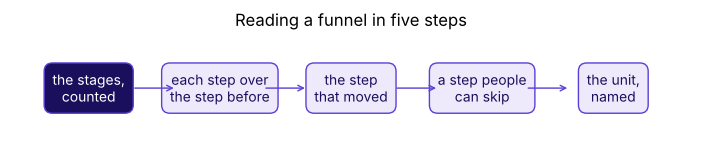

In [2]:
# The map: the chapter's steps in order; this notebook starts on the lit one and walks them all.
steps = ["the stages,\ncounted", "each step over\nthe step before", "the step\nthat moved", "a step people\ncan skip", "the unit,\nnamed"]
fig, ax = plt.subplots(figsize=(8.8, 1.4))
for i, s in enumerate(steps):
    ax.text(i, 0, s, ha="center", va="center", fontsize=10, color="white" if i == 0 else "#1A0F5C",
            bbox=dict(boxstyle="round,pad=0.6", fc="#1A0F5C" if i == 0 else "#EEEAFB", ec="#5B3FD6"))
for i in range(1, len(steps)):
    ax.annotate("", xy=(i - 0.33, 0), xytext=(i - 0.67, 0), arrowprops=dict(arrowstyle="->", color="#5B3FD6"))
ax.set_xlim(-0.6, len(steps) - 0.4); ax.set_ylim(-0.7, 0.7); ax.axis("off")
ax.set_title("Reading a funnel in five steps"); plt.show()

## Which step owns this cycle's loss?

The college's main programme, last cycle against this one, counted in applications. **Predict
before you run.** The next cell draws both cycles; which step owns this cycle's loss?

- a) Shortlisting, the lowest step at 50 percent
- b) Offer acceptance, at 75 percent this cycle
- c) Joining, at 80 percent
- d) The test, which 200 applications never sit

cycle        2024  2025  2026
stage                        
applied       950  1000  1000
sat_test      760   800   800
shortlisted   380   400   400
accepted      342   360   300
joined        274   288   240


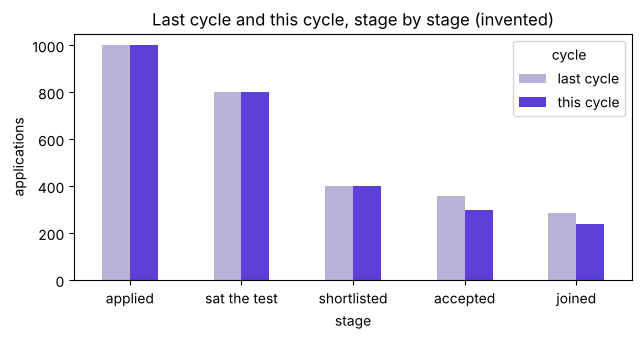

In [3]:
# The two cycles' funnels as bars, counted in applications.
main = adm.query("programme == 'main' and unit == 'applications' and group == 'all'")
counts = main.pivot_table(index="stage", columns="cycle", values="count", aggfunc="sum", sort=False).reindex(STAGES)
print(counts)
ax = counts[[2025, 2026]].rename(columns={2025: "last cycle", 2026: "this cycle"}).plot.bar(
    figsize=(7.2, 3.2), rot=0, color=["#B8B2D6", "#5B3FD6"])
ax.set_xticklabels(["applied", "sat the test", "shortlisted", "accepted", "joined"])
ax.set_ylabel("applications"); ax.set_title("Last cycle and this cycle, stage by stage (invented)"); plt.show()

## What does each step read?

By hand, this cycle, each step over the step before: 800 of 1,000 sat the test, 80 percent; 400
of 800 were shortlisted, 50; 300 of 400 accepted, 75; 240 of 300 joined, 80. **Drop-off** is 100
less the step rate: 20, 50, 25 and 20. The next cell writes the rule as a function, `step_rates`,
runs it on both cycles and checks it against the hand count.

In [4]:
# The rule as a function: each stage over the stage before; then drop-off and the overall rate.
def step_rates(stage_counts):
    """Each stage's count over the stage before it, in the same unit."""
    c = list(stage_counts)
    return [b / a for a, b in zip(c, c[1:])]

by_hand = [0.80, 0.50, 0.75, 0.80]
table = (100 * pd.DataFrame({cycle: step_rates(counts[cycle]) for cycle in [2025, 2026]}, index=STEPS)).round(1)
table["drop-off this cycle"] = 100 - table[2026]
print(table)
overall = {cycle: counts[cycle].iloc[-1] / counts[cycle].iloc[0] for cycle in [2025, 2026]}
print("overall, last stage over the first:", {k: round(100 * float(v), 1) for k, v in overall.items()})
check("the code's step rates equal the hand count: 80, 50, 75, 80",
      [round(r, 2) for r in step_rates(counts[2026])] == by_hand)
product = 1.0
for r in step_rates(counts[2026]):
    product *= r
check("the step rates multiply to the overall, 0.24", abs(product - overall[2026]) < 1e-12 and round(overall[2026], 2) == 0.24)
check("drop-off plus the step rate is 100 at every step", (table["drop-off this cycle"] + table[2026] == 100).all())

           2025  2026  drop-off this cycle
test       80.0  80.0                 20.0
shortlist  50.0  50.0                 50.0
accept     90.0  75.0                 25.0
join       80.0  80.0                 20.0
overall, last stage over the first: {2025: 28.8, 2026: 24.0}
PASS  the code's step rates equal the hand count: 80, 50, 75, 80
PASS  the step rates multiply to the overall, 0.24
PASS  drop-off plus the step rate is 100 at every step


**What happened.** The answer is b. Offer acceptance fell from 90 to 75 percent of those
shortlisted, and every other step read the same in both cycles. Shortlisting reads 50 percent
because the college selects half by design, and it did not move: when the overall falls, the
step that moved against its own past owns the fall, and a low, steady step is how the process
runs. **Named last, the formulas.** Step rate = those who reached a step ÷ those who reached
the step before, in one unit. Drop-off = 100 less the step rate. Overall conversion = the last
step ÷ the first: 240 ÷ 1,000 = 24 percent this cycle against 28.8 last cycle, and the step
rates multiply to it, 0.80 × 0.50 × 0.75 × 0.80 = 0.24.

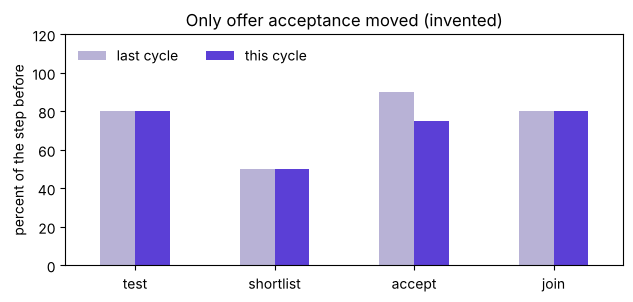

PASS  only the acceptance step moved, by 15 points


In [5]:
# Each step this cycle against the same step last cycle: one pair of bars differs.
ax = table[[2025, 2026]].rename(columns={2025: "last cycle", 2026: "this cycle"}).plot.bar(
    figsize=(7.2, 3.0), rot=0, color=["#B8B2D6", "#5B3FD6"])
ax.set_ylabel("percent of the step before"); ax.set_ylim(0, 120); ax.legend(frameon=False, ncol=2, loc="upper left")
ax.set_title("Only offer acceptance moved (invented)"); plt.show()
moved = (table[2026] - table[2025]).abs()
check("only the acceptance step moved, by 15 points", list(moved[moved > 1].index) == ["accept"] and moved["accept"] == 15)

## Why does one step pass 100 percent?

The college's sister programme (invented) makes its entrance test optional: of 1,000
applications, 300 sat the test, and 320 were shortlisted, 230 who sat the test and 90 on school
results alone. **The plausible wrong answer.** "Test to shortlist reads 107 percent, our best
step." 320 ÷ 300 puts 90 students who never sat the test over the test-takers. A rate above 100
says the numerator holds people the denominator never had: here, students who skipped the test;
elsewhere, a double count, two units or two time windows. The 107 is an **artefact**, a number
made by the way the count is taken.
**The fix** counts the shortlist among those who sat the test.

In [6]:
# The sister programme: the artefact, the fix, and a true number that answers another question.
sis = adm.query("programme == 'sister'").set_index(["group", "stage"])["count"]
artefact = sis[("all", "shortlisted")] / sis[("all", "sat_test")]
fixed = sis[("sat the test", "shortlisted")] / sis[("all", "sat_test")]
print(f"test to shortlist as printed: {100 * artefact:.1f} percent")
print(f"shortlisted among those who sat the test: {100 * fixed:.1f} percent")
print(f"shortlisted over applications: {100 * sis[('all', 'shortlisted')] / sis[('all', 'applied')]:.0f} percent")
check("the printed step is above 100 percent and the fixed one below it", artefact > 1 > fixed)
check("the fix reads 77 percent among test-takers", round(100 * fixed) == 77)

test to shortlist as printed: 106.7 percent
shortlisted among those who sat the test: 76.7 percent
shortlisted over applications: 32 percent
PASS  the printed step is above 100 percent and the fixed one below it
PASS  the fix reads 77 percent among test-takers


## Per application or per applicant?

This cycle's 1,000 applications came from 900 applicants, since some applied in two rounds.
**Predict before you run.** Joined over the top of the funnel, per applicant against per
application, reads:

- a) Higher per applicant
- b) Lower per applicant
- c) The same, since the joiners are the same 240
- d) Above 100 percent per applicant

unit         applications  applicants
stage                                
applied              1000         900
sat_test              800         760
shortlisted           400         390
accepted              300         300
joined                240         240


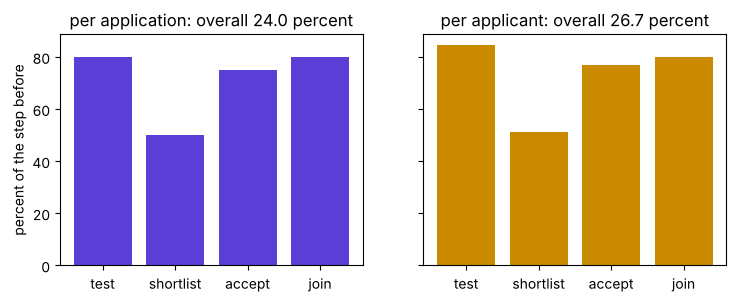

           applications  applicants
test               80.0        84.4
shortlist          50.0        51.3
accept             75.0        76.9
join               80.0        80.0
PASS  in this data every step reads at least as high per applicant; only the overall is sure to
PASS  joined per applicant 26.7 percent against 24.0 per application


In [7]:
# The same funnel in two units, side by side, with the overall rate in each.
this = adm.query("programme == 'main' and cycle == 2026 and group == 'all'")
units = this.pivot_table(index="stage", columns="unit", values="count", aggfunc="sum", sort=False).reindex(STAGES)
print(units)
by_unit = pd.DataFrame({u: step_rates(units[u]) for u in units.columns}, index=STEPS)
fig, axes = plt.subplots(1, 2, figsize=(8.6, 3.0), sharey=True)
for ax, u, colour in zip(axes, ["applications", "applicants"], ["#5B3FD6", "#C98A00"]):
    ax.bar(STEPS, 100 * by_unit[u], color=colour)
    ax.set_title(f"per {u[:-1]}: overall {100 * units[u].iloc[-1] / units[u].iloc[0]:.1f} percent")
axes[0].set_ylabel("percent of the step before"); plt.show()
print((100 * by_unit).round(1))
check("in this data every step reads at least as high per applicant; only the overall is sure to",
      (by_unit["applicants"] >= by_unit["applications"]).all())
check("joined per applicant 26.7 percent against 24.0 per application",
      [round(100 * units[u].iloc[-1] / units[u].iloc[0], 1) for u in ("applicants", "applications")] == [26.7, 24.0])

**What happened.** The answer is a: 240 joiners are 24 percent of applications and 26.7 percent
of applicants. Each applicant joins at most once, so the overall reads higher per person. In this
data every middle step reads at least as high per applicant too; that is this data's pattern, and
a middle step can move either way, so its direction is read from the data, and a chart names its
unit.

## Your turn: did any step move in the cycle before last?

**Your turn.** The file also holds 2024, the cycle before last. In the empty cell, run
`step_rates` on 2024's counts, compute its overall rate, and say whether any step differs from
2025's by more than a point.

```python
step_rates(counts[2024]), counts[2024].iloc[-1] / counts[2024].iloc[0]
```

**Check your cell against this one.** It sets 2024 beside 2025 step by step, then counts every
check this notebook has run.

In [8]:
# 2024 against 2025, step by step; then every check in this notebook counted.
r24, r25 = step_rates(counts[2024]), step_rates(counts[2025])
print(pd.DataFrame({"2024": [round(100 * r, 1) for r in r24], "2025": [round(100 * r, 1) for r in r25]}, index=STEPS))
check("every 2024 step is within a point of 2025's, so the acceptance fall is new this cycle",
      all(abs(a - b) <= 0.01 for a, b in zip(r24, r25)))
print(f"{sum(RESULTS)} of {len(RESULTS)} checks pass")

           2024  2025
test       80.0  80.0
shortlist  50.0  50.0
accept     90.0  90.0
join       80.1  80.0
PASS  every 2024 step is within a point of 2025's, so the acceptance fall is new this cycle
9 of 9 checks pass


## What does an analyst check at every step of a funnel?

1. Each step divides by the step before, in one named unit, and drop-off is 100 less that rate.
2. The overall rate divides the last step by the first, and where each stage is a subset of the
   one before, the step rates multiply to it.
3. When the overall falls, the step that moved against its own past owns the fall; a low, steady
   step is how the process runs, and where to invest is a separate question.
4. A rate above 100 percent means the numerator holds people the denominator never had: a
   skipped step, a double count, or mixed units or windows; count only those who passed the step
   before.

**In the interview.** [S] "Checkout conversion fell this month; how do you find where?" Check the
count first, then read each step over the step before in one named unit against its own past,
split by platform, group and date, and name the step that moved beside a step that held.

**What comes next.** Notebook 07 reads Gold's order flow on the event log with the same four
rules. Notebook 08 asks which of the college's two problems the dean fixes first.